# Trial History Effect on Response Time
**List of contents:**\
1- SJ\
2- TOJ

In [1]:
library(tidyverse)
library(ggpubr)
library(rstatix)
library(readxl)
library(dplyr)
library(broom)
library(ggplot2)

Warning message:
"package 'ggplot2' was built under R version 4.4.3"
── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   4.0.3     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: 'rstatix'


The following object is masked from 'package:stats':

    filter




###############################################################\
###############################################################
# 1- SJ
**List of contents:**\
1-1 Prior Stimulus\
1-2 Prior Response

###############################################################
## 1-1 Prior Stimulus

In [2]:
###############################################################
# Load SJ serial dependence dataset (prepared previously)
###############################################################

df <- read_xlsx("files/SJ_prior_stimulus_data.xlsx")

In [3]:
head(df)

participant,pre_stim,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,auditory_leading,-400,asynchrony,1.4373420
1,auditory_leading,-400,asynchrony,1.1699982
1,auditory_leading,-400,asynchrony,1.2704500
1,auditory_leading,-400,asynchrony,1.0868608
1,auditory_leading,-400,asynchrony,0.9859973
1,auditory_leading,-400,asynchrony,0.9527494


In [4]:
df <- df %>% group_by(participant, pre_stim, SOA) %>% 
    summarise(RT = mean(rt)) %>% ungroup()

`summarise()` has grouped output by 'participant', 'pre_stim'. You can override using the `.groups` argument.


In [5]:
colnames(df)[2] <- "trial_leading"

In [6]:
anova_test(
  data = df,
  dv = RT,
  wid = participant,          # Within-subject identifier
  within = c(trial_leading,SOA) # Within-subject factor
)

,Effect,DFn,DFd,F,p,p<.05,ges
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
1,trial_leading,1,17,0.920,3.51e-01,,8.08e-05
2,SOA,22,374,4.980,1.14e-11,*,5.60e-02
3,trial_leading:SOA,22,374,1.264,1.92e-01,,4.00e-03


In [8]:
df %>% group_by(SOA) %>% t_test(RT~trial_leading, paired=TRUE) %>% adjust_pvalue(method = "fdr") %>% mutate('p.adj<.05'=ifelse(p.adj<.05,'*',''))

SOA,.y.,group1,group2,n1,n2,statistic,df,p,p.adj,p.adj<.05
<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
-400,RT,auditory_leading,visual_leading,18,18,-0.26796639,17,0.7920,0.8698182,
-300,RT,auditory_leading,visual_leading,18,18,1.61502463,17,0.1250,0.5888000,
-250,RT,auditory_leading,visual_leading,18,18,0.21597960,17,0.8320,0.8698182,
-200,RT,auditory_leading,visual_leading,18,18,-2.31415145,17,0.0334,0.3841000,
-150,RT,auditory_leading,visual_leading,18,18,1.19821805,17,0.2470,0.6210000,
-120,RT,auditory_leading,visual_leading,18,18,-1.59960404,17,0.1280,0.5888000,
-100,RT,auditory_leading,visual_leading,18,18,-0.41557617,17,0.6830,0.8267895,
-80,RT,auditory_leading,visual_leading,18,18,0.21925056,17,0.8290,0.8698182,
-60,RT,auditory_leading,visual_leading,18,18,2.67875947,17,0.0159,0.3657000,


png 
  2

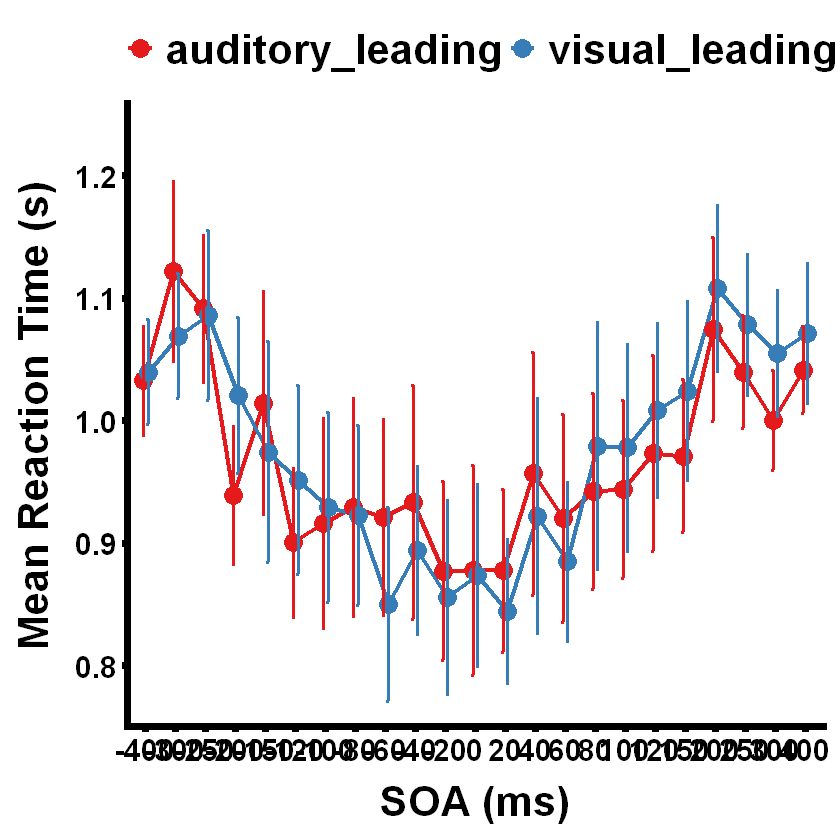

In [41]:
# Save plot
pdf(file="figures/SJ_prior_stimulus_RT.pdf", 
    width = 20, height = 10)  

# Compute mean and standard error of reaction times (RT)
df2 <- df %>% 
  group_by(SOA, trial_leading) %>% 
  summarize(
    meanRT = mean(RT, na.rm = TRUE),
    seRT = sd(RT, na.rm = TRUE) / sqrt(n()),
    .groups = 'drop'
  ) %>%
  mutate(SOA = factor(SOA))

# Compute significance for paired comparisons within each SOA level
stat.test <- df %>%
  group_by(SOA) %>%
  t_test(RT ~ trial_leading, paired = TRUE) %>%
  adjust_pvalue(method = "bonferroni") %>%
  add_significance("p.adj") %>%
  filter(p.adj < 0.05) %>%
  add_xy_position(x = "SOA", dodge = 0.8, step.increase = 0.08)

# Set significance bracket position slightly above the highest error bar
y_max <- max(df2$meanRT + df2$seRT, na.rm = TRUE)
stat.test$y.position <- y_max * 1.05

# Generate publication-style line plot with error bars
p <- ggplot(df2, aes(x = SOA, y = meanRT, color = trial_leading)) +
  # Trend lines connecting points
  geom_line(aes(group = trial_leading), linewidth = 1.2, position = position_dodge(0.3)) +
  
  # Mean points
  geom_point(size = 5, position = position_dodge(0.3)) +
  
  # Error bars representing standard error
  geom_errorbar(
    aes(ymin = meanRT - seRT, ymax = meanRT + seRT),
    width = 0.2,
    linewidth = 1.0,
    position = position_dodge(0.3)
  ) +
  
  # Axis and legend labels
  labs(
    x = "SOA (ms)",
    y = "Mean Reaction Time (s)",
    color = ""
  ) +
  
  # Color palette
  scale_color_brewer(palette = "Set1") +
  
  # Apply clean publication-style theme
  theme_classic(base_size = 14) +
  theme(
    legend.position = "top",
    legend.text = element_text(face = "bold", size = 25, color = "black"),
    axis.title.x = element_text(face = "bold", size = 25, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 25, margin = margin(r = 12)),
    axis.text.x  = element_text(face = "bold", size = 18, color = "black"),
    axis.text.y  = element_text(face = "bold", size = 18, color = "black"),
    axis.line    = element_line(linewidth = 2),
    axis.ticks   = element_line(linewidth = 2),
    plot.margin  = unit(c(10, 10, 10, 10), "pt")
  ) +
  
  # Add padding to top of y axis to accommodate significance bars
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15)))

# Add statistical significance stars if any comparison is significant
if(nrow(stat.test) > 0){
  p <- p + 
    stat_pvalue_manual(
      stat.test,
      label = "p.adj.signif", # Adjusted significance star format
      tip.length = 0.05,
      bracket.size = 1.0,     # Bolder brackets
      bracket.nudge.y = 0,
      bracket.shorten = 0.1,
      size = 8,               # Bold star size
      label.size = 20,
      vjust = -0.2
    )
}

p
dev.off()
print(p)

###############################################################
## 1-2 Prior Response

In [9]:
###############################################################
# Load SJ serial dependence dataset (prepared previously)
###############################################################

df <- read_xlsx("files/SJ_prior_response_data.xlsx")

In [10]:
head(df)

participant,pre_resp,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,asynchrony,-400,asynchrony,1.437342
1,asynchrony,-400,asynchrony,1.169998
1,asynchrony,-400,asynchrony,1.236840
1,asynchrony,-400,asynchrony,1.186734
1,asynchrony,-400,asynchrony,1.403907
1,asynchrony,-400,asynchrony,1.069756


In [11]:
df <- df %>% group_by(participant,, pre_resp, SOA) %>% 
    summarise(RT = mean(rt)) %>% ungroup()

`summarise()` has grouped output by 'participant', 'pre_resp'. You can override using the `.groups` argument.


In [12]:
colnames(df)[2] <- "trial_leading"

In [13]:
anova_test(
  data = df,
  dv = RT,
  wid = participant,          # Within-subject identifier
  within = c(trial_leading,SOA) # Within-subject factor
)

,Effect,DFn,DFd,F,p,p<.05,ges
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
1,trial_leading,1,17,16.783,7.52e-04,*,0.013
2,SOA,22,374,4.626,1.35e-10,*,0.054
3,trial_leading:SOA,22,374,1.113,3.29e-01,,0.005


In [14]:
 df %>% group_by(SOA) %>% t_test(RT~trial_leading, paired=TRUE)  %>% adjust_pvalue(method = "fdr") %>% mutate('p.adj<.05'=ifelse(p.adj<.05,'*',''))

SOA,.y.,group1,group2,n1,n2,statistic,df,p,p.adj,p.adj<.05
<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
-400,RT,asynchrony,synchrony,18,18,3.18842863,17,0.00538,0.0309350,*
-300,RT,asynchrony,synchrony,18,18,2.41754588,17,0.02710,0.0805000,
-250,RT,asynchrony,synchrony,18,18,-0.34124268,17,0.73700,0.8071905,
-200,RT,asynchrony,synchrony,18,18,1.09146315,17,0.29000,0.3923529,
-150,RT,asynchrony,synchrony,18,18,2.41907750,17,0.02710,0.0805000,
-120,RT,asynchrony,synchrony,18,18,0.80509574,17,0.43200,0.5229474,
-100,RT,asynchrony,synchrony,18,18,3.26095760,17,0.00460,0.0309350,*
-80,RT,asynchrony,synchrony,18,18,1.24967374,17,0.22800,0.3277500,
-60,RT,asynchrony,synchrony,18,18,3.03866619,17,0.00742,0.0341320,*


png 
  2

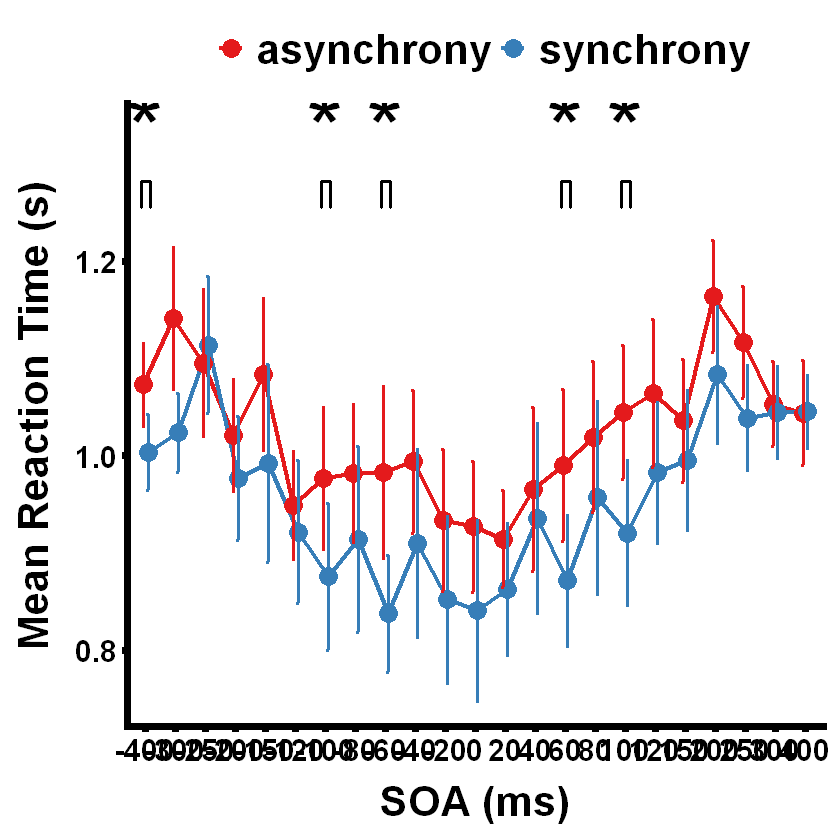

In [50]:
# Save plot
pdf(file="figures/SJ_prior_response_RT.pdf", 
    width = 20, height = 10) 


# Compute mean and standard error of reaction times (RT)
df2 <- df %>% 
  group_by(SOA, trial_leading) %>% 
  summarize(
    meanRT = mean(RT, na.rm = TRUE),
    seRT = sd(RT, na.rm = TRUE) / sqrt(n()),
    .groups = 'drop'
  ) %>%
  mutate(SOA = factor(SOA))

# Compute significance for paired comparisons within each SOA level
stat.test <- df %>%
  group_by(SOA) %>%
  t_test(RT ~ trial_leading, paired = TRUE) %>%
  adjust_pvalue(method = "fdr") %>%
  add_significance("p.adj") %>%
  filter(p.adj < 0.05) %>%
  add_xy_position(x = "SOA", dodge = 0.8, step.increase = 0.08)

# Set significance bracket position slightly above the highest error bar
y_max <- max(df2$meanRT + df2$seRT, na.rm = TRUE)
stat.test$y.position <- y_max * 1.05

# Generate publication-style line plot with error bars
p <- ggplot(df2, aes(x = SOA, y = meanRT, color = trial_leading)) +
  # Trend lines connecting points
  geom_line(aes(group = trial_leading), linewidth = 1.2, position = position_dodge(0.3)) +
  
  # Mean points
  geom_point(size = 5, position = position_dodge(0.3)) +
  
  # Error bars representing standard error
  geom_errorbar(
    aes(ymin = meanRT - seRT, ymax = meanRT + seRT),
    width = 0.2,
    linewidth = 1.0,
    position = position_dodge(0.3)
  ) +
  
  # Axis and legend labels
  labs(
    x = "SOA (ms)",
    y = "Mean Reaction Time (s)",
    color = ""
  ) +
  
  # Color palette
  scale_color_brewer(palette = "Set1") +
  
  # Apply clean publication-style theme
  theme_classic(base_size = 14) +
  theme(
    legend.position = "top",
    legend.text = element_text(face = "bold", size = 25, color = "black"),
    axis.title.x = element_text(face = "bold", size = 25, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 25, margin = margin(r = 12)),
    axis.text.x  = element_text(face = "bold", size = 18, color = "black"),
    axis.text.y  = element_text(face = "bold", size = 18, color = "black"),
    axis.line    = element_line(linewidth = 2),
    axis.ticks   = element_line(linewidth = 2),
    plot.margin  = unit(c(10, 10, 10, 10), "pt")
  ) +
  
  # Add padding to top of y axis to accommodate significance bars
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15)))

# Add statistical significance stars if any comparison is significant
if(nrow(stat.test) > 0){
  p <- p + 
    stat_pvalue_manual(
      stat.test,
      label = "p.adj.signif", # Adjusted significance star format
      tip.length = 0.05,
      bracket.size = 1.0,     # Bolder brackets
      bracket.nudge.y = 0,
      bracket.shorten = 0.1,
      size = 8,               # Bold star size
      label.size = 20,
      vjust = -0.2
    )
}

p
dev.off()
print(p)

###############################################################\
###############################################################
# 2- TOJ
**List of contents:**\
1-1 Prior Stimulus\
1-2 Prior Response

###############################################################
## 2-1 Prior Stimulus

In [15]:
df <- read_xlsx("files/TOJ_prior_stimulus_data.xlsx")
head(df)

participant,pre_stim,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,auditory_leading,-400,a,1.537577
1,auditory_leading,-400,a,1.454046
1,auditory_leading,-400,a,1.503926
1,auditory_leading,-400,a,1.504481
1,auditory_leading,-400,a,1.069864
1,auditory_leading,-400,a,1.638146


In [16]:
df <- df %>% group_by(participant, pre_stim, SOA) %>% 
    summarise(RT = mean(rt)) %>% ungroup()

`summarise()` has grouped output by 'participant', 'pre_stim'. You can override using the `.groups` argument.


In [17]:
colnames(df)[2] <- "trial_leading"

In [18]:
anova_test(
  data = df,
  dv = RT,
  wid = participant,          # Within-subject identifier
  within = c(trial_leading,SOA) # Within-subject factor
)

,Effect,DFn,DFd,F,p,p<.05,ges
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
1,trial_leading,1,17,1.734,2.05e-01,,0.000437
2,SOA,22,374,4.406,6.30e-10,*,0.041000
3,trial_leading:SOA,22,374,1.180,2.62e-01,,0.006000


In [19]:
df %>% group_by(SOA) %>% t_test(RT~trial_leading, paired=TRUE) %>% adjust_pvalue(method = "fdr") %>% mutate('p.adj<.05'=ifelse(p.adj<.05,'*',''))

SOA,.y.,group1,group2,n1,n2,statistic,df,p,p.adj,p.adj<.05
<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
-400,RT,auditory_leading,visual_leading,18,18,-1.63335702,17,0.1210,0.3478750,
-300,RT,auditory_leading,visual_leading,18,18,0.35672295,17,0.7260,0.8619524,
-250,RT,auditory_leading,visual_leading,18,18,1.18378918,17,0.2530,0.6465556,
-200,RT,auditory_leading,visual_leading,18,18,1.93538206,17,0.0698,0.2983429,
-150,RT,auditory_leading,visual_leading,18,18,0.29756530,17,0.7700,0.8619524,
-120,RT,auditory_leading,visual_leading,18,18,1.79306234,17,0.0908,0.2983429,
-100,RT,auditory_leading,visual_leading,18,18,-0.05507037,17,0.9570,0.9570000,
-80,RT,auditory_leading,visual_leading,18,18,0.55741446,17,0.5850,0.8496471,
-60,RT,auditory_leading,visual_leading,18,18,0.90103525,17,0.3800,0.7743333,


png 
  2

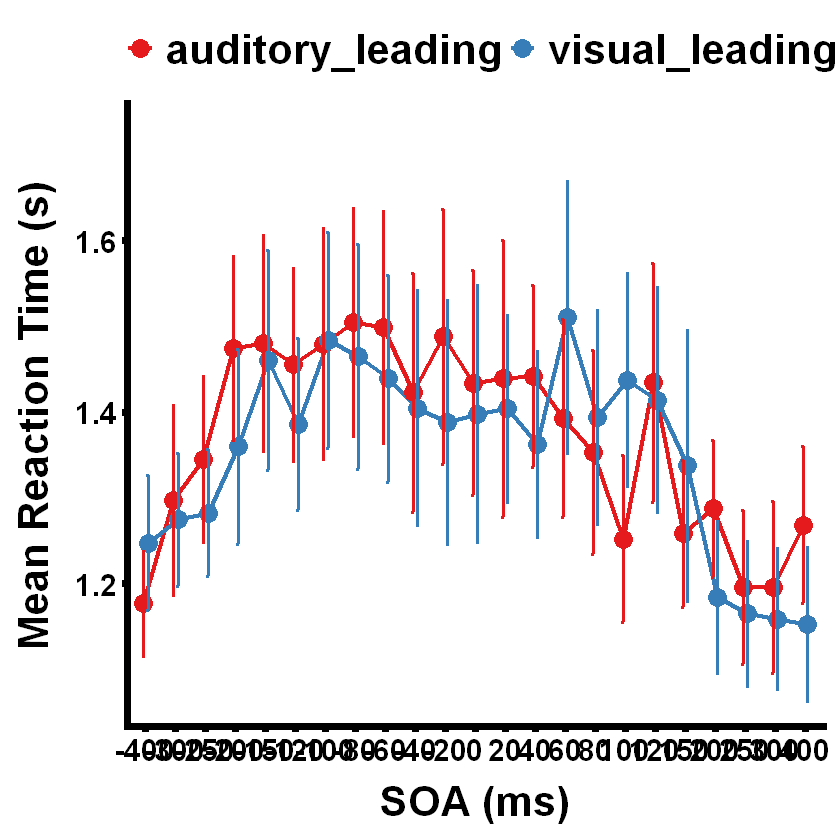

In [21]:
# Save plot
pdf(file="files/TOJ_prior_stimulus_RT.pdf", 
    width = 20, height = 10) 


# Compute mean and standard error of reaction times (RT)
df2 <- df %>% 
  group_by(SOA, trial_leading) %>% 
  summarize(
    meanRT = mean(RT, na.rm = TRUE),
    seRT = sd(RT, na.rm = TRUE) / sqrt(n()),
    .groups = 'drop'
  ) %>%
  mutate(SOA = factor(SOA))

# Compute significance for paired comparisons within each SOA level
stat.test <- df %>%
  group_by(SOA) %>%
  t_test(RT ~ trial_leading, paired = TRUE) %>%
  adjust_pvalue(method = "fdr") %>%
  add_significance("p.adj") %>%
  filter(p.adj < 0.05) %>%
  add_xy_position(x = "SOA", dodge = 0.8, step.increase = 0.08)

# Set significance bracket position slightly above the highest error bar
y_max <- max(df2$meanRT + df2$seRT, na.rm = TRUE)
stat.test$y.position <- y_max * 1.05

# Generate publication-style line plot with error bars
p <- ggplot(df2, aes(x = SOA, y = meanRT, color = trial_leading)) +
  # Trend lines connecting points
  geom_line(aes(group = trial_leading), linewidth = 1.2, position = position_dodge(0.3)) +
  
  # Mean points
  geom_point(size = 5, position = position_dodge(0.3)) +
  
  # Error bars representing standard error
  geom_errorbar(
    aes(ymin = meanRT - seRT, ymax = meanRT + seRT),
    width = 0.2,
    linewidth = 1.0,
    position = position_dodge(0.3)
  ) +
  
  # Axis and legend labels
  labs(
    x = "SOA (ms)",
    y = "Mean Reaction Time (s)",
    color = ""
  ) +
  
  # Color palette
  scale_color_brewer(palette = "Set1") +
  
  # Apply clean publication-style theme
  theme_classic(base_size = 14) +
  theme(
    legend.position = "top",
    legend.text = element_text(face = "bold", size = 25, color = "black"),
    axis.title.x = element_text(face = "bold", size = 25, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 25, margin = margin(r = 12)),
    axis.text.x  = element_text(face = "bold", size = 18, color = "black"),
    axis.text.y  = element_text(face = "bold", size = 18, color = "black"),
    axis.line    = element_line(linewidth = 2),
    axis.ticks   = element_line(linewidth = 2),
    plot.margin  = unit(c(10, 10, 10, 10), "pt")
  ) +
  
  # Add padding to top of y axis to accommodate significance bars
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15)))

# Add statistical significance stars if any comparison is significant
if(nrow(stat.test) > 0){
  p <- p + 
    stat_pvalue_manual(
      stat.test,
      label = "p.adj.signif", # Adjusted significance star format
      tip.length = 0.05,
      bracket.size = 1.0,     # Bolder brackets
      bracket.nudge.y = 0,
      bracket.shorten = 0.1,
      size = 8,               # Bold star size
      label.size = 20,
      vjust = -0.2
    )
}

p
dev.off()
print(p)

###############################################################
## 2-2 Prior Response

In [22]:
df <- read_xlsx("files/TOJ_prior_response_data.xlsx")
head(df)

participant,pre_resp,SOA,resp,rt
<dbl>,<chr>,<dbl>,<chr>,<dbl>
1,a,-400,a,1.4540460
1,a,-400,a,1.5044811
1,a,-400,a,1.0698638
1,a,-400,a,1.3872484
1,a,-300,a,0.8524889
1,a,-300,a,1.3702865


In [23]:
df <- df %>% group_by(participant, pre_resp, SOA) %>% 
    summarise(RT = mean(rt)) %>% ungroup()

`summarise()` has grouped output by 'participant', 'pre_resp'. You can override using the `.groups` argument.


In [24]:
colnames(df)[2] <- "trial_leading"

In [25]:
df$trial_leading <- ifelse(df$trial_leading=="v",'visual response', "auditory response")

In [26]:
anova_test(
  data = df,
  dv = RT,
  wid = participant,          # Within-subject identifier
  within = c(trial_leading,SOA) # Within-subject factor
)

,Effect,DFn,DFd,F,p,p<.05,ges
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
1,trial_leading,1,17,1.631,2.19e-01,,0.002
2,SOA,22,374,5.235,1.91e-12,*,0.047
3,trial_leading:SOA,22,374,1.571,5.00e-02,,0.008


In [27]:
df %>% group_by(SOA) %>% t_test(RT~trial_leading, paired=TRUE) %>% adjust_pvalue(method = "fdr") %>% mutate('p.adj<.05'=ifelse(p.adj<.05,'*',''))

SOA,.y.,group1,group2,n1,n2,statistic,df,p,p.adj,p.adj<.05
<dbl>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
-400,RT,auditory response,visual response,18,18,-0.4701458,17,0.64400,0.7463500,
-300,RT,auditory response,visual response,18,18,0.5157512,17,0.61300,0.7463500,
-250,RT,auditory response,visual response,18,18,-0.5496531,17,0.59000,0.7463500,
-200,RT,auditory response,visual response,18,18,-1.1044060,17,0.28500,0.7283333,
-150,RT,auditory response,visual response,18,18,2.2179507,17,0.04050,0.1863000,
-120,RT,auditory response,visual response,18,18,-0.4637954,17,0.64900,0.7463500,
-100,RT,auditory response,visual response,18,18,1.0036784,17,0.33000,0.7463500,
-80,RT,auditory response,visual response,18,18,-0.4823607,17,0.63600,0.7463500,
-60,RT,auditory response,visual response,18,18,0.3796976,17,0.70900,0.7548182,


png 
  2

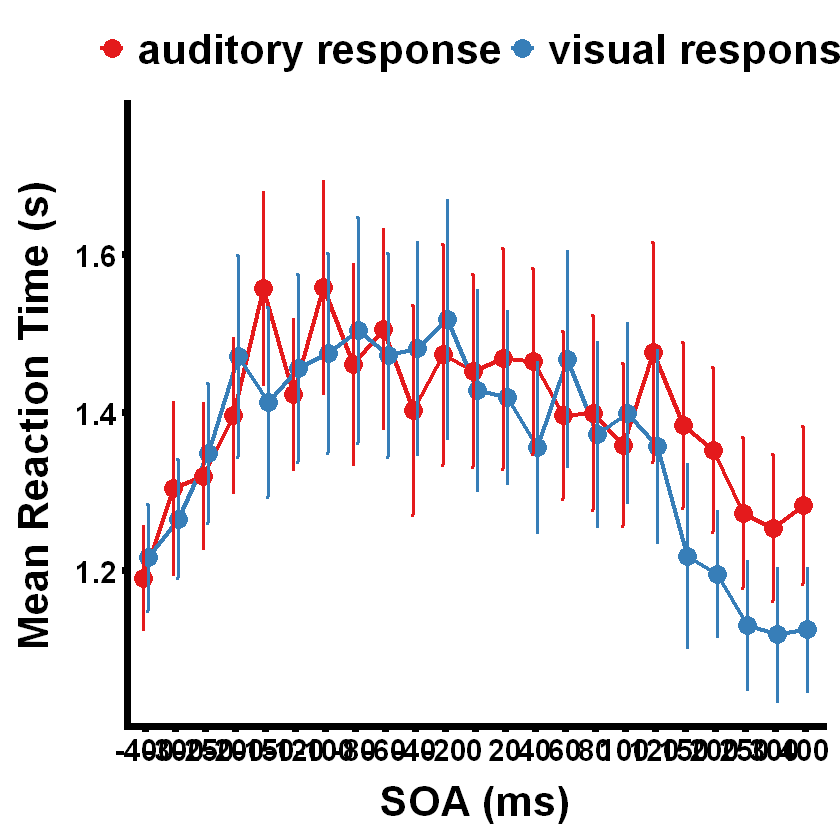

In [75]:
# Save plot
pdf(file="figures/TOJ_prior_response_RT.pdf", 
    width = 20, height = 10) 

# Compute mean and standard error of reaction times (RT)
df2 <- df %>% 
  group_by(SOA, trial_leading) %>% 
  summarize(
    meanRT = mean(RT, na.rm = TRUE),
    seRT = sd(RT, na.rm = TRUE) / sqrt(n()),
    .groups = 'drop'
  ) %>%
  mutate(SOA = factor(SOA))

# Compute significance for paired comparisons within each SOA level
stat.test <- df %>%
  group_by(SOA) %>%
  t_test(RT ~ trial_leading, paired = TRUE) %>%
  adjust_pvalue(method = "fdr") %>%
  add_significance("p.adj") %>%
  filter(p.adj < 0.05) %>%
  add_xy_position(x = "SOA", dodge = 0.8, step.increase = 0.08)

# Set significance bracket position slightly above the highest error bar
y_max <- max(df2$meanRT + df2$seRT, na.rm = TRUE)
stat.test$y.position <- y_max * 1.05

# Generate publication-style line plot with error bars
p <- ggplot(df2, aes(x = SOA, y = meanRT, color = trial_leading)) +
  # Trend lines connecting points
  geom_line(aes(group = trial_leading), linewidth = 1.2, position = position_dodge(0.3)) +
  
  # Mean points
  geom_point(size = 5, position = position_dodge(0.3)) +
  
  # Error bars representing standard error
  geom_errorbar(
    aes(ymin = meanRT - seRT, ymax = meanRT + seRT),
    width = 0.2,
    linewidth = 1.0,
    position = position_dodge(0.3)
  ) +
  
  # Axis and legend labels
  labs(
    x = "SOA (ms)",
    y = "Mean Reaction Time (s)",
    color = ""
  ) +
  
  # Color palette
  scale_color_brewer(palette = "Set1") +
  
  # Apply clean publication-style theme
  theme_classic(base_size = 14) +
  theme(
    legend.position = "top",
    legend.text = element_text(face = "bold", size = 25, color = "black"),
    axis.title.x = element_text(face = "bold", size = 25, margin = margin(t = 10)),
    axis.title.y = element_text(face = "bold", size = 25, margin = margin(r = 12)),
    axis.text.x  = element_text(face = "bold", size = 18, color = "black"),
    axis.text.y  = element_text(face = "bold", size = 18, color = "black"),
    axis.line    = element_line(linewidth = 2),
    axis.ticks   = element_line(linewidth = 2),
    plot.margin  = unit(c(10, 10, 10, 10), "pt")
  ) +
  
  # Add padding to top of y axis to accommodate significance bars
  scale_y_continuous(expand = expansion(mult = c(0.05, 0.15)))

# Add statistical significance stars if any comparison is significant
if(nrow(stat.test) > 0){
  p <- p + 
    stat_pvalue_manual(
      stat.test,
      label = "p.adj.signif", # Adjusted significance star format
      tip.length = 0.05,
      bracket.size = 1.0,     # Bolder brackets
      bracket.nudge.y = 0,
      bracket.shorten = 0.1,
      size = 8,               # Bold star size
      label.size = 20,
      vjust = -0.2
    )
}

p
dev.off()
print(p)